## Use L1 if you are not sure that all features are relevant or not and let the model drop the feaures if required, then use L1 else use L2

Welcome to Machine Learning. Think of **Regularization** as a speed governor or a gentle tax on your model's complexity.

## 1. The Core Problem: Why We Need Regularization

When a machine learning model tries too hard to fit the training data, it overfits. It memorizes noise and quirks rather than underlying patterns, leading to huge weights ($w$) and poor performance on unseen test data.

**Regularization** adds a penalty term to the loss function that discourages the model's parameters ($w$) from growing too large.

## 2. The Intuition & Mathematics

A standard Loss Function (like Mean Squared Error) measures prediction error:

$$
\text{Total Loss} = \text{Loss}(\text{Data}, w)
$$

With regularization, we modify it by adding a penalty on weight magnitudes:

$$
\text{Regularized Loss} = \text{Loss}(\text{Data}, w) + \lambda \times \text{Penalty}(w)
$$

Where $\lambda \ge 0$ is a hyperparameter that controls how strongly we penalize large weights.

### L2 Regularization (Ridge)

L2 penalizes the **squared sum of weights**.

$$
\text{Loss}_{\text{L2}} = \text{MSE} + \lambda \sum_{j=1}^p w_j^2
$$

- **Geometric Intuition:** The L2 constraint forms a smooth, round hypersphere ($w_1^2 + w_2^2 \le C$).
- **Effect:** It shrinks all weights toward zero smoothly, but almost **never forces them to exact zero**. It keeps every feature involved, just scaled down.

### L1 Regularization (Lasso)

L1 penalizes the **absolute sum of weights**.

$$
\text{Loss}_{\text{L1}} = \text{MSE} + \lambda \sum_{j=1}^p \vert{}w_j\vert{}
$$

- **Geometric Intuition:** The L1 constraint forms a diamond shape with sharp corners on the coordinate axes ($\vert{}w_1\vert{} + \vert{}w_2\vert{} \le C$).
- **Effect:** Optimization loss contours hit these sharp corners first. This forces irrelevant or redundant feature weights directly to **exact zero**, performing automatic **feature selection**.

## 3. Comparison, Pros & Cons

| Feature | L1 Regularization (Lasso) | L2 Regularization (Ridge) |
| --- | --- | --- |
| **Penalty Term** | $\lambda \sum \Vert{}w_j\Vert{}$ | $\lambda \sum w_j^2$ |
| **Sparsity** | **Yes** (drives weights to exact $0$) | **No** (shrinks weights close to $0$) |
| **Feature Selection** | Built-in (drops useless features) | Keeps all features |
| **Correlated Features** | Arbitrarily picks one feature and zeroes others | Distributes weight evenly across correlated features |
| **Differentiability** | Non-differentiable at $w=0$ (uses subgradients) | Smoothly differentiable everywhere |
| **Best Used When** | High dimensions with sparse true signals | Most features have small, continuous effects |

## 4. Practical Considerations

- **Always Scale Your Features First:** L1 and L2 penalties directly depend on parameter scale. Standardize features (e.g., via `StandardScaler`) before training so large feature units don't artificially skew penalty terms.
- **Tuning $\lambda$ (Alpha):** Use Cross-Validation (e.g., `GridSearchCV` or `LassoCV`/`RidgeCV` in scikit-learn).
- $\lambda = 0$: Standard model without regularization (risk of overfitting).
- $\lambda$ too large: Model underfits, driving weights too close to zero.
- **ElasticNet (The Hybrid Solution):** Combines both penalties ($\alpha \cdot \text{L1} + (1-\alpha) \cdot \text{L2}$). Use ElasticNet when you suspect correlated features but still want feature selection benefits.

********************************************

#### Que- Why in overfit case the weights grows, explain me with example

To understand why weights blow up during overfitting, let's start with a simple mental picture: **a model's weight ($w$) represents how aggressively it reacts to a feature ($x$).**

If $w$ is small, changes in $x$ cause small changes in prediction. If $w$ is huge, a tiny tweak in $x$ causes massive spikes in prediction.

### The Intuition: Chasing the Noise

Every real-world dataset consists of two things:

1. **Signal:** The true underlying pattern (e.g., larger houses cost more).
2. **Noise:** Random fluctuations or measurement errors (e.g., a seller was desperate and sold a big house cheap, or a buyer overpaid for a tiny apartment).

When a model overfits, it stops learning just the signal and starts **memorizing every exact data point**, including the noise. To force a smooth curve or line to wiggle violently enough to hit every noisy point, the model has to multiply inputs by **extreme positive and negative factors**.

### A Concrete Mathematical Example

Imagine predicting home price ($y$) based on size ($x_1$) and age ($x_2$).

Suppose we have two neighboring houses that are nearly identical in size, but due to random noise, house B sold for much less than house A:

- **House A:** Size $x_1 = 100$, Age $x_2 = 5$ $\rightarrow$ Price $y = \$500\text{k}$
- **House B:** Size $x_1 = 100$, Age $x_2 = 5.01$ $\rightarrow$ Price $y = \$300\text{k}$ (Noise/Anomalous sale)

#### 1. A Simple, Well-Fit Model (Small Weights)

A regularized model ignores the noise and fits the signal:

$$
y \approx 4.5 x_1 + 10
$$

- **Weights:** $w_1 = 4.5, w_2 = 0$
- **Predictions:**
- House A: $4.5(100) + 10 = \$460\text{k}$
- House B: $4.5(100) + 10 = \$460\text{k}$
- **Result:** Small errors on training data, but it captures the general rule for new houses.

#### 2. The Overfit Model (Huge Weights)

An unconstrained, complex model tries to get **zero error** on both training points:

$$
y = 5 x_1 - 20,000 (x_2 - 5)
$$

- **Weights:** $w_1 = 5, w_2 = -20,000$
- **Predictions:**
- House A: $5(100) - 20,000(5 - 5) = \$500\text{k}$ (Exact match!)
- House B: $5(100) - 20,000(5.01 - 5) = 500 - 200 = \$300\text{k}$ (Exact match!)

To force a $\$200\text{k}$ price drop over a tiny **0.01-year age difference**, the model was forced to crank $w_2$ up to **$-20,000$**.

### What Happens on New (Test) Data?

Now test this overfit model on a new house:

- **House C (New):** Size $x_1 = 100$, Age $x_2 = 5.02$

$$
\text{Predicted Price} = 5(100) - 20,000(5.02 - 5) = 500 - 400 = \$100\text{k}
$$

Because $w_2$ grew to $-20,000$, a minuscule $0.02$ change in age wiped out $\$400,000$ of value. The model is hyper-sensitive and completely fails in the real world.

### Key Takeaways

- **Large weights equal high sensitivity:** Massive weights are the mathematical mechanism a model uses to create steep wiggles and sharp cliffs in order to memorize individual noisy points.
- **Regularization ($L1/L2$) caps weight growth:** By penalizing large weights, regularization prevents the model from setting $w_2 = -20,000$, forcing it to accept small errors on noisy training points to preserve generalizability.

************************************

#### Que- Effect: It shrinks all weights toward zero smoothly, but almost never forces them to exact zero. It keeps every feature involved, just scaled down.- Help me understand it with examples and more intitution.

To understand why **L2 (Ridge)** shrinks weights smoothly without setting them to exact zero, let's look at how it behaves dynamically through gradient updates, geometry, and a numerical example.

### 1. Intuition: The Shrinkage Factor

In L2 regularization, the loss function penalizes the **squared size** of the weights:

$$
\text{Total Loss} = \text{MSE} + \lambda (w_1^2 + w_2^2 + \dots)
$$

When updating the weights using gradient descent, the math reveals something special:

$$
w_{\text{new}} = w_{\text{old}} \cdot \underbrace{(1 - \alpha \lambda)}_{\text{Shrinkage Factor}} - \alpha \cdot (\text{MSE Gradient})
$$

- $\alpha$ is the learning rate, and $\lambda$ is the regularization strength.
- The term $(1 - \alpha \lambda)$ is a number slightly less than $1$ (for example, $0.95$).

In every step, L2 **multiplies the current weight by a fraction** before making its standard gradient update.

#### The Halving Paradox (Zeno's Effect)

If you start with $w = 100$ and multiply it by $0.9$ repeatedly:

$$
100 \rightarrow 90 \rightarrow 81 \rightarrow 72.9 \rightarrow \dots \rightarrow 0.000000001
$$

The weight gets extraordinarily small ($0.0000001$), but **multiplying a non-zero number by a fraction never equals absolute zero**.

### 2. Concrete Example: House Price Prediction

Imagine predicting house prices using two features:

1. **Square Footage ($x_1$):** Crucial factor.
2. **Paint Quality ($x_2$):** Slightly helpful, but minor.

#### Without Regularization

- $w_1 = 150$
- $w_2 = 12$

#### With L1 (Lasso) Regularization

L1 subtracts a **constant step** from weights in every iteration. It decides paint quality isn't important enough to keep around:

- $w_1 = 142$
- $w_2 = \mathbf{0.0}$ *(Completely eliminated - Feature Selection)*

#### With L2 (Ridge) Regularization

L2 applies a **percentage tax** proportional to weight size. Large weights get heavily taxed, while small weights get taxed very lightly:

- $w_1 = 110$ *(Shrunk down to prevent overfitting)*
- $w_2 = \mathbf{0.8}$ *(Shrunk significantly, but preserved!)*

**Why keep paint quality at 0.8 instead of 0?** Because as $w_2$ gets close to zero (e.g., $w_2 = 0.8$), its L2 penalty ($0.8^2 = 0.64$) becomes almost harmless. The model decides that keeping $w_2 = 0.8$ helps lower prediction error slightly, without incurring any meaningful penalty cost.

### 3. Geometric Intuition

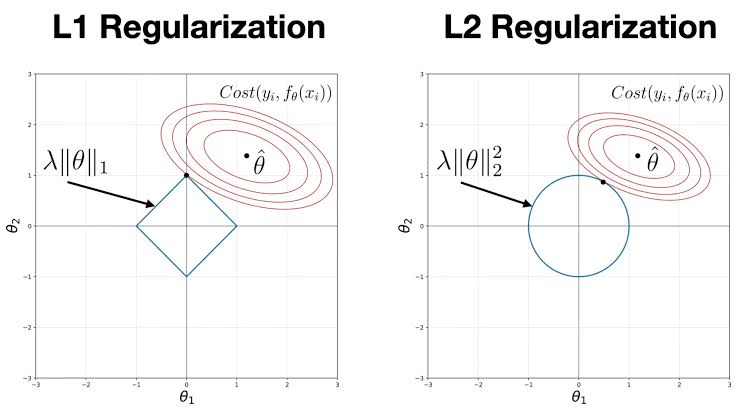

- **L1 Constraint (Diamond):** Has sharp corners sitting directly on the axes where $w_1 = 0$ or $w_2 = 0$. Optimization contours naturally touch these pointy corners, snapping weights to exact zero.
- **L2 Constraint (Circle):** The smooth sphere has **no corners on the axes**. The loss contours touch the circular boundary at arbitrary, smooth points off the axes. As a result, both $w_1$ and $w_2$ remain non-zero.

### Summary Table

| Perspective | L1 Regularization (Lasso) | L2 Regularization (Ridge) |
| --- | --- | --- |
| **Mathematical Push** | Subtracts a fixed amount ($\text{step} \propto \text{sign}(w)$) | Scales down by a fraction ($\text{step} \propto w$) |
| **As Weight Approaches 0** | Force remains strong; pushes it across $0$ | Force vanishes to $0$; soft landing near $0$ |
| **Outcome** | **Sparsity:** Sets irrelevant features to exact $0$ | **Smooth Shrinkage:** Keeps all features, scaled down |

*************************

#### Que- L2 applies a percentage tax proportional to weight size. Large weights get heavily taxed, while small weights get taxed very lightly:- explain it more in easy to understand

Think of L2 regularization like a progressive income tax on a weight's size: **the bigger a weight grows, the higher its penalty rate becomes.**

### The Squaring Effect ($w^2$)

L2 penalizes weights using their square ($w^2$). Squaring numbers creates an accelerating penalty:

- If weight $w = 2$, penalty is $2^2 = 4$
- If weight $w = 10$, penalty jumps to $10^2 = \mathbf{100}$
- If weight $w = 100$, penalty explodes to $100^2 = \mathbf{10,000}$

Because of this quadratic growth, the model treats large weights as extreme financial emergencies that must be cut down immediately.

### Comparing L1 and L2 Side-by-Side

To see how L2's "taxation" differs, contrast it with L1 (Lasso) using a real-world scenario.

#### Scenario: Two Weights ($w_{\text{big}} = 10$ vs. $w_{\text{small}} = 1$)

- **L1 (Flat Step Penalty):** L1 takes away a fixed amount—say, $1$ unit—regardless of size.
- $w_{\text{big}} = 10 \rightarrow 9$ (Reduced by $10\%$)
- $w_{\text{small}} = 1 \rightarrow 0$ (Reduced by $100\%$, **wiped out!**)
- *Result:* L1 doesn't care if a weight is huge or tiny; it hits both with the exact same flat fee, crushing tiny weights completely.
- **L2 (Proportional Tax Penalty):** L2 reduces each weight by a percentage—say, $10\%$ of its current value.
- $w_{\text{big}} = 10 \rightarrow 9$ (Cut down by a large amount: **$1.0$**)
- $w_{\text{small}} = 1 \rightarrow 0.9$ (Cut down by a tiny amount: **$0.1$**)
- *Result:* L2 aggressively slashes the massive weight while barely touching the small weight.

### Why Small Weights Get "Taxed Lightly"

When a weight becomes very small (e.g., $w = 0.1$), its squared penalty becomes virtually zero:

$$
0.1^2 = 0.01
$$

At this level, the regularization penalty is so weak that it no longer forces the weight down any further. If the feature provides even a tiny bit of useful information to reduce prediction error, the model willingly keeps $w = 0.1$ around.

### Summary Analogy

- **L1 Regularization:** A strict **flat parking fine** ($50 for everyone). It instantly bankrupts people with small bank accounts ($w = 0.1 \rightarrow 0$).
- **L2 Regularization:** A **percentage wealth tax** ($10\%$ of total net worth). A billionaire ($w = 100$) pays a massive $\$10$ million penalty, while someone with $\$10$ ($w = 10$) pays only $\$1$, allowing them to keep surviving comfortably.

*************************

#### Que- In the loss function I see squared terms in L2 but the weight update doesn't have any squared terms, then how the above explanation makes sense i.e. L2 is reducing weight proportional to weight value whereas L1 is doing it flat

You have hit on the exact mathematical core of the topic. The reason the weight update doesn't have a squared term is due to **calculus** (taking the derivative).

During training, we don't update weights using the Loss Function directly; we update them using the **Gradient (Derivative)** of the Loss Function with respect to the weights.

### 1. The Derivative of $w^2$ is Linear ($2w$)

Let's look at what happens when you take the derivative of each penalty term with respect to $w$:

#### **L2 Penalty Derivative:**

$$
\text{L2 Penalty} = \lambda w^2
$$

$$
\frac{d}{dw}(\lambda w^2) = 2 \lambda w
$$

Notice that the exponent $2$ drops down, leaving $w$ to the power of $1$. The derivative is **directly proportional to $w$ itself**.

#### **L1 Penalty Derivative:**

$$
\text{L1 Penalty} = \lambda \vert{}w\vert{}
$$

$$
\frac{d}{dw}(\lambda \vert{}w\vert{}) = \lambda \cdot \text{sign}(w) = \begin{cases} +\lambda & \text{if } w \gt 0 \\ -\lambda & \text{if } w \lt 0 \end{cases}
$$

The derivative of $\vert{}w\vert{}$ is just a **constant value** ($+1$ or $-1$). It does not depend on the size of $w$ at all!

### 2. Plug Derivatives into Gradient Descent

The standard gradient descent rule updates weights by subtracting the derivative of the loss:

$$
w_{\text{new}} = w_{\text{old}} - \alpha \cdot \left( \frac{d\text{MSE}}{dw} + \frac{d\text{Penalty}}{dw} \right)
$$

Plugging in the derivatives of L1 and L2 shows why their behavior differs:

```
L1 Update (Flat Reduction):
w_new = w_old - α · (MSE Gradient) - α·λ · sign(w)
└──────┬──────┘
FLAT STEP (Constant Fee)

L2 Update (Proportional Reduction):
w_new = w_old - α · (MSE Gradient) - α·λ · (2w)
└─────┬─────┘
PROPORTIONAL TO w (Percentage Tax)

```

### 3. Comparing the Step Sizes Numerically

Let $\alpha \lambda = 0.1$ for simplicity. Look at how much each method subtracts based on weight size:

| Weight Size ($w$) | L1 Penalty Gradient ($\text{sign}(w)$) | L1 Subtraction Amount | L2 Penalty Gradient ($2w$) | L2 Subtraction Amount |
| --- | --- | --- | --- | --- |
| **$w = 100$** | $+1$ | **$-0.1$** | $+200$ | **$-20.0$** *(Aggressive slash!)* |
| **$w = 10$** | $+1$ | **$-0.1$** | $+20$ | **$-2.0$** |
| **$w = 1$** | $+1$ | **$-0.1$** | $+2$ | **$-0.2$** |
| **$w = 0.1$** | $+1$ | **$-0.1$** *(Direct hit to 0!)* | $+0.2$ | **$-0.02$** *(Gentle nudge)* |

### Why This Connects Back to the Intuition

- **In the Loss Function:** L2 penalizes large weights with a **squared error** ($w^2$).
- **In the Weight Update:** The derivative transforms that $w^2$ into a **linear pull ($2w$)**.
- **The Result:** Because the update term contains $w$, large weights experience a huge pull downward, while small weights experience a tiny pull downward—exactly like a percentage tax.

*****************************

#### Derivation of the L1 and L2 term in Loss function

Here is the step-by-step vector calculus derivation of the gradient of L1 regularization, explaining how we handle its non-differentiable points.

## 1. Objective & Setup

In vector notation, suppose we have a weight vector $\mathbf{w} = \begin{bmatrix} w_1 & w_2 & \dots & w_p \end{bmatrix}^T \in \mathbb{R}^p$.

The L1 regularization penalty term $R_{L1}(\mathbf{w})$ is defined as the **$\ell_1$-norm** of $\mathbf{w}$:

$$
R_{L1}(\mathbf{w}) = \lambda \Vert{}\mathbf{w}\Vert{}_1 = \lambda \sum_{j=1}^p \vert{}w_j\vert{}
$$

Our goal is to compute the gradient with respect to the weight vector:

$$
\nabla_{\mathbf{w}} R_{L1}(\mathbf{w}) = \begin{bmatrix} \frac{\partial R_{L1}}{\partial w_1} \\ \frac{\partial R_{L1}}{\partial w_2} \\ \vdots \\ \frac{\partial R_{L1}}{\partial w_p} \end{bmatrix}
$$

## 2. Scalar Derivative (Element-Wise)

Because the summation $\sum_{j=1}^p \vert{}w_j\vert{}$ is separable, taking the partial derivative with respect to a single weight $w_j$ depends only on $\vert{}w_j\vert{}$:

$$
\frac{\partial R_{L1}}{\partial w_j} = \lambda \frac{d}{d w_j} \vert{}w_j\vert{}
$$

Recall the definition of absolute value $\vert{}w_j\vert{}$:

$$
\vert{}w_j\vert{} = \begin{cases} w_j & \text{if } w_j \gt 0 \\ 0 & \text{if } w_j = 0 \\ -w_j & \text{if } w_j \lt 0 \end{cases}
$$

Taking the standard derivative for $w_j \neq 0$:

$$
\frac{d}{d w_j} \vert{}w_j\vert{} = \begin{cases} +1 & \text{if } w_j \gt 0 \\ -1 & \text{if } w_j \lt 0 \end{cases} = \text{sign}(w_j)
$$

## 3. The Non-Differentiable Point ($w_j = 0$) & Subgradient

At $w_j = 0$, the function $\vert{}w_j\vert{}$ forms a sharp "V" corner (a kink), meaning the standard derivative **does not exist**.

In vector calculus, we resolve this using a **Subgradient** ($\partial$). A subgradient of a convex function $f$ at a point $x_0$ is any vector $g$ that satisfies:

$$
f(x) \ge f(x_0) + g^T (x - x_0) \quad \forall x
$$

Geometrically, $g$ represents the slope of any tangent line that stays entirely on or below the graph of $f(x)$.

At $w_j = 0$, any slope between $-1$ and $+1$ forms a valid supporting line underneath the absolute value curve. Thus, the subdifferential (set of all subgradients) is:

$$
\partial \vert{}w_j\vert{} = \begin{cases} \{+1\} & \text{if } w_j \gt 0 \\ [-1, +1] & \text{if } w_j = 0 \\ \{-1\} & \text{if } w_j \lt 0 \end{cases}
$$

In practical implementation (e.g., subgradient descent), we assign $g_j = 0$ when $w_j = 0$.

## 4. Vector Formulation

Applying the element-wise result across all $p$ dimensions yields the full subgradient vector:

$$
\nabla_{\mathbf{w}} R_{L1}(\mathbf{w}) = \lambda \, \text{sign}(\mathbf{w})
$$

where $\text{sign}(\mathbf{w})$ is the element-wise sign function applied to the vector:

$$
\text{sign}(\mathbf{w}) = \begin{bmatrix} \text{sign}(w_1) \\ \text{sign}(w_2) \\ \vdots \\ \text{sign}(w_p) \end{bmatrix}
$$

## 5. Weight Update in Vector Form

Plugging this subgradient into the complete loss function gradient descent step:

$$
\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \alpha \nabla_{\mathbf{w}} \mathcal{L}_{\text{MSE}}(\mathbf{w}^{(t)}) - \alpha \lambda \, \text{sign}(\mathbf{w}^{(t)})
$$

### Key takeaway from the math:

The subgradient term $-\alpha \lambda \, \text{sign}(\mathbf{w})$ subtracts a constant vector step size $\alpha \lambda$ in the opposite direction of $\mathbf{w}$'s sign, driving individual elements directly to zero and forcing exact sparsity in the weight vector.

Here is the step-by-step vector calculus derivation of the gradient of L2 regularization, showing why its vector derivative remains smooth and differentiable everywhere.

## 1. Objective & Setup

In vector notation, suppose we have a weight vector $\mathbf{w} = \begin{bmatrix} w_1 & w_2 & \dots & w_p \end{bmatrix}^T \in \mathbb{R}^p$.

The L2 regularization penalty term $R_{L2}(\mathbf{w})$ is defined as the **squared $\ell_2$-norm** (Euclidean norm) of $\mathbf{w}$:

$$
R_{L2}(\mathbf{w}) = \frac{1}{2} \lambda \Vert{}\mathbf{w}\Vert{}_2^2 = \frac{1}{2} \lambda \sum_{j=1}^p w_j^2
$$

*(Note: We multiply by $\frac{1}{2}$ by convention to cancel out the exponent $2$ during differentiation.)*

Our goal is to compute the gradient vector with respect to $\mathbf{w}$:

$$
\nabla_{\mathbf{w}} R_{L2}(\mathbf{w}) = \begin{bmatrix} \frac{\partial R_{L2}}{\partial w_1} \\ \frac{\partial R_{L2}}{\partial w_2} \\ \vdots \\ \frac{\partial R_{L2}}{\partial w_p} \end{bmatrix}
$$

## 2. Scalar Derivative (Element-Wise)

Because the sum $\sum_{j=1}^p w_j^2$ is separable, taking the partial derivative with respect to a single weight component $w_j$ depends only on $w_j^2$:

$$
\frac{\partial R_{L2}}{\partial w_j} = \frac{\partial}{\partial w_j} \left( \frac{1}{2} \lambda w_j^2 \right) = \frac{1}{2} \lambda \cdot (2 w_j) = \lambda w_j
$$

Unlike L1, this function $w_j^2$ is a smooth parabola. Its derivative exists everywhere—including at $w_j = 0$, where $\frac{\partial}{\partial w_j} (0) = 0$.

## 3. Vector Calculus Derivation (Direct Matrix Form)

We can also express the squared $\ell_2$-norm as an inner product (dot product):

$$
R_{L2}(\mathbf{w}) = \frac{1}{2} \lambda (\mathbf{w}^T \mathbf{w})
$$

Using the standard vector calculus matrix derivative identity:

$$
\nabla_{\mathbf{w}} (\mathbf{w}^T \mathbf{A} \mathbf{w}) = (\mathbf{A} + \mathbf{A}^T) \mathbf{w}
$$

Setting $\mathbf{A} = \mathbf{I}$ (the identity matrix):

$$
\nabla_{\mathbf{w}} (\mathbf{w}^T \mathbf{w}) = 2 \mathbf{w}
$$

Multiplying by our constant $\frac{1}{2} \lambda$:

$$
\nabla_{\mathbf{w}} R_{L2}(\mathbf{w}) = \frac{1}{2} \lambda (2 \mathbf{w}) = \lambda \mathbf{w}
$$

## 4. Vector Form Comparison (L1 vs. L2)

Collecting element-wise partial derivatives gives us the complete gradient vector:

$$
\nabla_{\mathbf{w}} R_{L2}(\mathbf{w}) = \lambda \mathbf{w} = \lambda \begin{bmatrix} w_1 \\ w_2 \\ \vdots \\ w_p \end{bmatrix}
$$

| Property | L1 Gradient Vector | L2 Gradient Vector |
| --- | --- | --- |
| **Formula** | $\nabla R_{L1}(\mathbf{w}) = \lambda \, \text{sign}(\mathbf{w})$ | $\nabla R_{L2}(\mathbf{w}) = \lambda \mathbf{w}$ |
| **Differentiability** | Non-differentiable at $\mathbf{w} = \mathbf{0}$ | Smoothly differentiable everywhere |
| **Magnitude Dependance** | Fixed magnitude ($\lambda$), independent of $\Vert{}w_j\Vert{}$ | Magnitude scales linearly with $\Vert{}w_j\Vert{}$ |

## 5. Weight Update in Vector Form

Plugging this gradient into the complete loss function gradient descent step:

$$
\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \alpha \nabla_{\mathbf{w}} \mathcal{L}_{\text{MSE}}(\mathbf{w}^{(t)}) - \alpha \lambda \mathbf{w}^{(t)}
$$

Grouping the weight terms together reveals the **Weight Decay** property:

$$
\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} (1 - \alpha \lambda) - \alpha \nabla_{\mathbf{w}} \mathcal{L}_{\text{MSE}}(\mathbf{w}^{(t)})
$$

### Key takeaway from the math:

The term $(1 - \alpha \lambda)$ scales down the entire weight vector $\mathbf{w}$ by a constant percentage in every step before taking the MSE gradient step. As $\mathbf{w} \to \mathbf{0}$, the shrinkage term $\alpha \lambda \mathbf{w} \to \mathbf{0}$, ensuring a soft landing near zero without jumping across it.

**************************************

*****

## Elastic net regularization

Elastic Net regularization is a hybrid approach that combines both L1 (Lasso) and L2 (Ridge) penalties into a single loss function.

## 1. Why We Need Elastic Net (The Intuition)

While L1 and L2 are powerful individually, they both have critical limitations in specific scenarios:

- **The Problem with L1 (Lasso):** When features are highly correlated (e.g., house square footage and number of rooms), L1 arbitrarily picks **one** feature to keep and zeroes out the rest. Additionally, if the number of features ($p$) exceeds the number of observations ($n$), Lasso can select at most $n$ features.
- **The Problem with L2 (Ridge):** L2 shrinks correlated features together (group effect), but it never drives any weight to exact zero, meaning it cannot perform feature selection on high-dimensional noisy data.

**Elastic Net solves both issues simultaneously:**

1. It uses **L1** to force useless weights to exact zero (sparsity and feature selection).
2. It uses **L2** to handle correlated features gracefully by sharing weights among them (the grouping effect).

## 2. Comparison: L1 vs. L2 vs. Elastic Net

| Property | L1 (Lasso) | L2 (Ridge) | Elastic Net |
| --- | --- | --- | --- |
| **Penalty Type** | $\lambda \Vert{}\mathbf{w}\Vert{}_1$ | $\frac{1}{2} \lambda \Vert{}\mathbf{w}\Vert{}_2^2$ | $\lambda_1 \Vert{}\mathbf{w}\Vert{}_1 + \frac{1}{2} \lambda_2 \Vert{}\mathbf{w}\Vert{}_2^2$ |
| **Feature Selection** | Yes (Exact zeros) | No | Yes (Exact zeros) |
| **Correlated Features** | Arbitrarily keeps 1 feature, drops others | Distributes weights evenly across all | Groups correlated features and shrinks together |
| **Behavior when $p \gt n$** | Selects at most $n$ features | Keeps all $p$ features | Can select more than $n$ features |
| **Hyperparameters** | 1 ($\lambda$) | 1 ($\lambda$) | 2 ($\alpha$ total strength, $l_1\text{-ratio}$) |

## 3. Pros, Cons & Practical Considerations

**Pros:**

- Handles multicollinearity exceptionally well while keeping feature selection intact.
- Performs robustly on ultra-high dimensional datasets (e.g., genomics, text data where $p \gg n$).

**Cons:**

- **Double Hyperparameter Tuning:** Requires tuning two parameters instead of one, which increases cross-validation computation time.

**Practical Considerations (scikit-learn implementation):** In `scikit-learn`, the Elastic Net loss parameterization is controlled by `alpha` ($\alpha$) and `l1_ratio` ($\rho$):

$$
\text{Penalty} = \alpha \cdot \rho \cdot \Vert{}\mathbf{w}\Vert{}_1 + \frac{1}{2} \alpha \cdot (1 - \rho) \cdot \Vert{}\mathbf{w}\Vert{}_2^2
$$

- `l1_ratio = 1`: Equivalent to pure Lasso (L1).
- `l1_ratio = 0`: Equivalent to pure Ridge (L2).
- `0 < l1_ratio < 1`: Elastic Net behavior (a common starting guess is `l1_ratio = 0.5`).

## 4. Vector Calculus Derivation of Elastic Net

Let's derive the gradient/subgradient step-by-step using matrix-vector notation.

### Step 1: Define the Objective Function

Given a dataset matrix $\mathbf{X} \in \mathbb{R}^{n \times p}$, target vector $\mathbf{y} \in \mathbb{R}^n$, and weight vector $\mathbf{w} \in \mathbb{R}^p$:

$$
\mathcal{L}_{\text{ElasticNet}}(\mathbf{w}) = \underbrace{\frac{1}{2n} \Vert{}\mathbf{y} - \mathbf{X}\mathbf{w}\Vert{}_2^2}_{\text{MSE Loss}} + \underbrace{\lambda_1 \Vert{}\mathbf{w}\Vert{}_1}_{\text{L1 Penalty}} + \underbrace{\frac{1}{2} \lambda_2 \Vert{}\mathbf{w}\Vert{}_2^2}_{\text{L2 Penalty}}
$$

### Step 2: Differentiate the MSE Term

Expanding the Mean Squared Error term in vector form:

$$
f_{\text{MSE}}(\mathbf{w}) = \frac{1}{2n} (\mathbf{y} - \mathbf{X}\mathbf{w})^T (\mathbf{y} - \mathbf{X}\mathbf{w}) = \frac{1}{2n} \left( \mathbf{y}^T\mathbf{y} - 2\mathbf{w}^T\mathbf{X}^T\mathbf{y} + \mathbf{w}^T\mathbf{X}^T\mathbf{X}\mathbf{w} \right)
$$

Taking the gradient with respect to vector $\mathbf{w}$:

$$
\nabla_{\mathbf{w}} f_{\text{MSE}}(\mathbf{w}) = \frac{1}{n} \left( -\mathbf{X}^T\mathbf{y} + \mathbf{X}^T\mathbf{X}\mathbf{w} \right) = -\frac{1}{n} \mathbf{X}^T (\mathbf{y} - \mathbf{X}\mathbf{w})
$$

### Step 3: Differentiate the Regularization Terms

1. **L2 Gradient:** $$ \nabla_{\mathbf{w}} \left( \frac{1}{2} \lambda_2 \Vert{}\mathbf{w}\Vert{}_2^2 \right) = \lambda_2 \mathbf{w} $$

$$
2. **L1 Subgradient:** Since $\Vert{}\mathbf{w}\Vert{}_1 = \sum_{j=1}^p \vert{}w_j\vert{}$ is non-differentiable at $w_j = 0$, its subgradient is: $$ \partial_{\mathbf{w}} \left( \lambda_1 \Vert{}\mathbf{w}\Vert{}_1 \right) = \lambda_1 \, \text{sign}(\mathbf{w}) $$ where $\text{sign}(w_j) \in [-1, 1]$ if $w_j = 0$.

### Step 4: Combine into the Final Subgradient Update

Summing all three terms gives the complete subgradient of the Elastic Net loss:
$$

\partial_{\mathbf{w}} \mathcal{L}_{\text{ElasticNet}}(\mathbf{w}) = -\frac{1}{n} \mathbf{X}^T (\mathbf{y} - \mathbf{X}\mathbf{w}) + \lambda_2 \mathbf{w} + \lambda_1 \, \text{sign}(\mathbf{w})

$$
Plugging this into the gradient descent update equation:
$$

\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \gamma \left( -\frac{1}{n} \mathbf{X}^T (\mathbf{y} - \mathbf{X}\mathbf{w}^{(t)}) + \lambda_2 \mathbf{w}^{(t)} + \lambda_1 \, \text{sign}(\mathbf{w}^{(t)}) \right)

$$
Regrouping terms to highlight **weight shrinkage**:
$$

\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} (1 - \gamma \lambda_2) + \frac{\gamma}{n} \mathbf{X}^T (\mathbf{y} - \mathbf{X}\mathbf{w}^{(t)}) - \gamma \lambda_1 \, \text{sign}(\mathbf{w}^{(t)})
$$

### Summary of the Gradient Mechanics

- The $(1 - \gamma \lambda_2)$ factor applies **L2 proportional shrinkage**, keeping correlated weight groups stable.
- The $-\gamma \lambda_1 \, \text{sign}(\mathbf{w})$ term applies **L1 constant subtraction**, driving uninformative weights down to exact zero.

*************

In `scikit-learn`'s `ElasticNet`, **`alpha` ($\alpha$) is the hyperparameter that controls the overall strength of the regularization penalty.**

It scales how heavily the combined model parameters are penalized relative to the standard Mean Squared Error (MSE) loss.

### The Mathematical Role of `alpha`

The overall loss function optimized by `ElasticNet` in scikit-learn is:

$$
\mathcal{L}(\mathbf{w}) = \frac{1}{2n} \Vert{}\mathbf{y} - \mathbf{X}\mathbf{w}\Vert{}_2^2 + \mathbf{\alpha} \cdot \left( \rho \Vert{}\mathbf{w}\Vert{}_1 + \frac{1 - \rho}{2} \Vert{}\mathbf{w}\Vert{}_2^2 \right)
$$

where:

- **`alpha` ($\alpha$):** The total multiplier for regularization.
- **`l1_ratio` ($\rho$):** The mixing parameter between L1 and L2 (ranging from 0 to 1).

Notice how **`alpha` is multiplied across the entire penalty block**:

- **If `alpha = 0`:** Regularization is completely disabled. The model becomes standard Ordinary Least Squares (OLS) Linear Regression, carrying a high risk of overfitting.
- **If `alpha` is small (e.g., $0.01$):** Light regularization. Weights shrink slightly, keeping high model capacity.
- **If `alpha` is large (e.g., $10.0$):** Heavy regularization. Weights are severely penalized, shrinking towards zero (risk of underfitting).

### How `alpha` Interacts with `l1_ratio`

Think of `alpha` and `l1_ratio` as a two-knob system:

1. **`alpha` (Volume Knob):** Sets *how much total penalty* to apply.
2. **`l1_ratio` (Balance Knob):** Sets *how to divide* that penalty between L1 (Lasso) and L2 (Ridge).

```
ElasticNet(alpha=1.0, l1_ratio=0.5)
│          │          └─> 50% L1 (Lasso) + 50% L2 (Ridge)
│          └────────────> Total penalty intensity factor = 1.0

```

- Pure Lasso equivalent: `l1_ratio=1.0` (L1 penalty weight = `alpha`)
- Pure Ridge equivalent: `l1_ratio=0.0` (L2 penalty weight = `0.5 * alpha`)

### Practical Considerations

- **Always tune `alpha` via Cross-Validation:** Instead of setting `alpha` manually, use **`ElasticNetCV`**, which automatically searches across a grid of `alpha` values to find the optimal balance for your test performance.
- **Feature Scaling:** Because `alpha` penalizes absolute weight magnitudes, you **must standardize your input features** (e.g., using `StandardScaler`) prior to fitting. Otherwise, features with larger numeric scales will be unfairly penalized.

****************

#### Que- Explain how L1 creates diamond, L2 creates circle and elastic creates rounded diamond

The geometric shapes of regularization arise directly from setting a fixed budget $C$ on the penalty term in a 2D weight space $(w_1, w_2)$.

## 1. L2 Regularization: The Circle

The L2 penalty caps the sum of squared weights:

$$
w_1^2 + w_2^2 \le C
$$

### Why it creates a Circle

This equation is identical to the standard Cartesian equation of a circle centered at the origin with radius $R = \sqrt{C}$:

$$
x^2 + y^2 = R^2
$$

Every point $(w_1, w_2)$ that satisfies $w_1^2 + w_2^2 = C$ sits at an equal Euclidean distance from $(0,0)$.

- **Boundary:** Completely smooth everywhere with no corners.
- **Effect:** Loss contours touch this circular boundary at arbitrary points, keeping both $w_1 \neq 0$ and $w_2 \neq 0$.

## 2. L1 Regularization: The Diamond

The L1 penalty caps the sum of absolute values:

$$
\vert{}w_1\vert{} + \vert{}w_2\vert{} \le C
$$

### Why it creates a Diamond

Because of the absolute value function, we split the equation across the 4 quadrants:

- **Quadrant 1** ($w_1 \gt 0, w_2 \gt 0$): $w_1 + w_2 = C \implies w_2 = -w_1 + C$ (line with slope $-1$)
- **Quadrant 2** ($w_1 \lt 0, w_2 \gt 0$): $-w_1 + w_2 = C \implies w_2 = w_1 + C$ (line with slope $+1$)
- **Quadrant 3** ($w_1 \lt 0, w_2 \lt 0$): $-w_1 - w_2 = C \implies w_2 = -w_1 - C$ (line with slope $-1$)
- **Quadrant 4** ($w_1 \gt 0, w_2 \lt 0$): $w_1 - w_2 = C \implies w_2 = w_1 - C$ (line with slope $+1$)

Connecting these 4 straight linear segments produces a diamond (or square tilted by $45^\circ$).

- **Corners:** The sharp vertices sit directly on the axes at $(C, 0)$, $(-C, 0)$, $(0, C)$, and $(0, -C)$.
- **Effect:** Elliptical loss contours are highly likely to hit these sharp corners first during optimization, setting one weight to exact zero (e.g., $w_2 = 0$).

## 3. Elastic Net: The Rounded Diamond

Elastic Net combines both constraints into a single equation:

$$
\lambda_1 (\vert{}w_1\vert{} + \vert{}w_2\vert{}) + \lambda_2 (w_1^2 + w_2^2) \le C
$$

### Why it creates a Rounded Diamond

This shape is a mathematical blend of the linear absolute value bounds and the quadratic squared bounds:

1. **At the Axes (Corners):** The L1 term $\vert{}w_1\vert{} + \vert{}w_2\vert{}$ dominates when weights are near zero, preserving the sharp, pointed vertices on the coordinate axes.
2. **Along the Edges:** The L2 term $w_1^2 + w_2^2$ adds curvature, bowing the flat diamond lines outward into convex curves.

The resulting constraint region is a **diamond with curved, rounded edges**.

- **Why this matters visually:** The pointed vertices on the axes still allow loss contours to hit exact zeros (feature selection from L1), while the rounded edges prevent severe instability when features are strongly correlated (grouping effect from L2).

****************************************************
****************************************************

**Que**- explain me is it true to say that L2 will give a better model fit and less error compared to L1, if yes, explain why and help me develop intuition

**No, it is not universally true that L2 will give a better model fit or less error than L1.**

Whether L2 outperforms L1 (or vice versa) depends entirely on the **underlying structure of your data**—specifically, how many features actually contribute to the true pattern.

### The Core Rule: Dense vs. Sparse True Signals

To build intuition, think of your features as signals mixed with noise.

- **L2 performs better when the truth is DENSE:** Almost all features have small-to-medium real contributions to the outcome.
- **L1 performs better when the truth is SPARSE:** Only a small subset of features actually matter, while the rest are completely irrelevant noise.

### Why L2 Wins in a Dense World

Imagine predicting a person's overall health score using 100 features like sleep duration, diet metrics, step count, age, blood pressure, etc.

- **The Reality:** Almost every feature has some minor, real effect on health. None of them are zero.
- **How L2 Handles It:** L2 shrinks all 100 weights smoothly down to small non-zero numbers (e.g., $w \approx 0.05$). It keeps every piece of information working together.
- **Why L1 Struggles Here:** L1 will aggressively force 70 or 80 of those features to exact $0$. By throwing away features that actually contained real information, L1 incurs higher prediction error than L2.

### Why L1 Wins in a Sparse World

Imagine analyzing 10,000 genetic markers to predict a specific disease, but in reality, only 12 specific genes cause the condition. The other 9,988 genes are pure random noise.

- **The Reality:** Most features should have a true weight of zero.
- **How L1 Handles It:** L1 acts like a filter. It sets the 9,988 useless noise features to **exact zero** ($w_j = 0$), leaving only the 12 relevant genes in the equation.
- **Why L2 Struggles Here:** L2 cannot set weights to exact zero. It will keep all 10,000 genes in the model with tiny weights (e.g., $w = 0.001$). Even though each noise weight is tiny, **summing up tiny errors across 9,988 noisy features creates huge total prediction error**, leading to overfitting.

### Summary Intuition

| Scenario | True Data Structure | Winner | Why? |
| --- | --- | --- | --- |
| **Many weak predictors** | Dense | **L2 (Ridge)** | Preserves every minor signal; averaging many small signals beats discarding them. |
| **Few strong predictors + Lots of noise** | Sparse | **L1 (Lasso)** | Wipes out noise completely; L2 lets noise leak into the final prediction. |
| **Correlated features** | Redundant | **L2 (Ridge)** | Smoothly averages credit across correlated features; L1 randomly keeps one and drops the rest. |

### The Practical Solution: Elastic Net

Since you rarely know whether your real-world data is dense or sparse beforehand, **Elastic Net** bridges the gap. By combining both penalties ($\text{L1} + \text{L2}$), it allows the model to drop completely useless noise features (L1 behavior) while smoothly shrinking and grouping the remaining useful features (L2 behavior).